# Text-to-SQL with Retrieval-Augmented Generation

Dataset: `gretelai/synthetic_text_to_sql` (100,000 training and 5,851 test examples). Parts of this notebook were written with AI assistance.

The notebook has two parts, executed in order.

| Part | Content | Author |
|---|---|---|
| 1 | Data cleaning, exploratory data analysis and split generation | Person 1 |
| 2 | Retrieval-augmented generation: indexing, retrieval comparison, evaluation | Person 2 |

**Part 1** cleans both official splits, generates the stratified train, validation and test ID files, and produces the EDA figures and the filter report. Outputs: `test_ids.json`, `val_ids.json`, `train_ids.json`, `excluded_ids.json`, `filter_report.json` and four figures.

**Part 2** builds the retrieval index from the clean training split only and compares zero-shot generation, random few-shot examples, dense, BM25, hybrid (reciprocal rank fusion), masked-question and skeleton retrieval on the validation set. The selected configuration is evaluated once on the test set. Metric: execution accuracy, with paired-bootstrap confidence intervals.

Shared modules: `data.py` (dataset loading, SQL execution sandbox, result comparison, cleaning and split utilities) and `config.py` (seed, model names, run mode).

# Part 1: Data cleaning and EDA 

### 1.0 Setup

In [1]:
import sys, json, re, time, random, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(".").resolve()))

import data
from data import run_sql, same_result

from config import CONFIG, SEED, QUICK_RUN, set_seed
set_seed()

# Split sizes and file names of the shared ID files
TEST_SIZE, VAL_SIZE, QUICK_TEST = 200, 200, 20
test_ids_path, val_ids_path, train_ids_path = Path("test_ids.json"), Path("val_ids.json"), Path("train_ids.json")

_notebook_start = time.time()
CACHE = Path("clean_data"); CACHE.mkdir(exist_ok=True)

print("Imports OK.")
print(f"Dataset  : {CONFIG['dataset']}")
print(f"Seed     : {SEED}")
print(f"QUICK_RUN: {QUICK_RUN}")

Imports OK.
Dataset  : gretelai/synthetic_text_to_sql
Seed     : 42
QUICK_RUN: False


### 1.1 Raw dataset overview

In [2]:
ds = data.load_data()
raw_train, raw_test = ds["train"], ds["test"]

print(f"Official train split : {len(raw_train):>8,d} rows")
print(f"Official test split  : {len(raw_test):>8,d} rows")
print(f"\nColumns: {raw_train.column_names}")

required = ["id", "domain", "sql_complexity", "sql_prompt", "sql_context", "sql"]
print("\nMissing / blank values in key columns (train):")
for col in required:
    n = sum(1 for v in raw_train[col] if v is None or str(v).strip() == "")
    print(f"  {col:<25} {'[OK]' if n == 0 else f'[WARN] {n}'}")

print("\nSample test row:")
ex = raw_test[0]
for col in required:
    print(f"  {col:<15}: {str(ex[col])[:80]}")

Official train split :  100,000 rows
Official test split  :    5,851 rows

Columns: ['id', 'domain', 'domain_description', 'sql_complexity', 'sql_complexity_description', 'sql_task_type', 'sql_task_type_description', 'sql_prompt', 'sql_context', 'sql', 'sql_explanation']

Missing / blank values in key columns (train):
  id                        [OK]
  domain                    [OK]
  sql_complexity            [OK]
  sql_prompt                [OK]
  sql_context               [OK]
  sql                       [OK]

Sample test row:
  id             : 1
  domain         : artificial intelligence
  sql_complexity : basic SQL
  sql_prompt     : What is the average explainability score of creative AI applications in 'Europe'
  sql_context    : CREATE TABLE creative_ai (application_id INT, name TEXT, region TEXT, explainabi
  sql            : SELECT AVG(explainability_score) FROM creative_ai WHERE region IN ('Europe', 'No


### 1.2 Manual exclusions
Examples that pass all automated checks but are semantically incorrect are listed in `excluded_ids.json` (fields `id`, `split`, `reason`) and removed before splitting. The file is initialised with the pre-flagged example (id 4323); a file in the earlier `{"test": {...}}` layout is converted to the current layout.

In [3]:
excluded_path = Path("excluded_ids.json")
BRICS = {"id": 4323, "split": "test",
         "reason": "Gold query ignores the BRICS country filter - performs an inner join without a WHERE clause, "
                   "returning all rows from military_innovation instead of only BRICS countries."}

def _normalise_exclusions(payload):
    """Return exclusions in the {test_exclusions, train_exclusions} layout (also reads the {test: {id: reason}} layout)."""
    out = {"test_exclusions": [], "train_exclusions": []}
    for split in ("test", "train"):
        raw = payload.get(f"{split}_exclusions") or payload.get(split) or []
        items = raw.items() if isinstance(raw, dict) else \
            [((e["id"], e.get("reason", "")) if isinstance(e, dict) else (e, "")) for e in raw]
        out[f"{split}_exclusions"] = [{"id": int(i), "split": split, "reason": r} for i, r in items]
    if 4323 not in {e["id"] for e in out["test_exclusions"]}:
        out["test_exclusions"].append(BRICS)
    return out

payload = json.load(open(excluded_path, encoding="utf-8")) if excluded_path.exists() else {}
with open(excluded_path, "w", encoding="utf-8") as f:
    json.dump(_normalise_exclusions(payload), f, indent=2)
print(f"Exclusion file: {excluded_path}")

excluded_ids = data.load_excluded_ids(excluded_path)
print(f"Manual exclusions loaded: {len(excluded_ids)} IDs from {excluded_path}")

with open(excluded_path, encoding="utf-8") as f:
    excl = json.load(f)
print(f"\n  Test exclusions : {len(excl.get('test_exclusions', []))}")
print(f"  Train exclusions: {len(excl.get('train_exclusions', []))}")
for e in excl.get("test_exclusions", []):
    print(f"\n  [Pre-flagged] ID {e['id']} ({e.get('split', 'test')})")
    print(f"  Reason: {e.get('reason', '')}")

Exclusion file: excluded_ids.json
Manual exclusions loaded: 1 IDs from excluded_ids.json

  Test exclusions : 1
  Train exclusions: 0

  [Pre-flagged] ID 4323 (test)
  Reason: Gold query ignores the BRICS country filter - performs an inner join without a WHERE clause, returning all rows from military_innovation instead of only BRICS countries.


### 1.3 Clean the official test split (5,851 rows)
`data.clean_split` keeps a gold query only if it is a SELECT/WITH, runs without error, and returns a non-trivial result. Every removed example is logged with its reason.

In [4]:
print(f"Cleaning official test split ({len(raw_test):,} rows)...\n")
clean_test, test_log = data.clean_split(raw_test, "test", excluded_ids, show_progress=True)
print(f"\nResult: {len(clean_test):,} clean  |  {len(test_log):,} removed")

def categorize(reason: str) -> str:
    r = reason.lower()
    if "manual" in r: return "Manual exclusion"
    if "non-read" in r or "does not start" in r: return "Write / non-SELECT op"
    if "context setup" in r: return "Context setup error"
    if "sql execution" in r: return "SQL execution error"
    if "empty result" in r: return "Empty result ([])"
    if "trivial" in r: return "Trivial result"
    return "Other"

test_reason_counts = Counter(categorize(e["reason"]) for e in test_log)
print("\nRemoval breakdown -- test split:")
print(f"  {'Reason':<40} {'Count':>6}  {'%':>6}")
print("  " + "-" * 56)
for reason, count in test_reason_counts.most_common():
    print(f"  {reason:<40} {count:>6,d}  {count / len(raw_test) * 100:>5.1f}%")
print(f"\n  Total clean pool: {len(clean_test):,} ({len(clean_test) / len(raw_test) * 100:.1f}%)")

Cleaning official test split (5,851 rows)...

  test: 5,851/5,851 | clean: 3,078 | removed: 2,773   

Result: 3,078 clean  |  2,773 removed

Removal breakdown -- test split:
  Reason                                    Count       %
  --------------------------------------------------------
  SQL execution error                       1,052   18.0%
  Write / non-SELECT op                       613   10.5%
  Empty result ([])                           592   10.1%
  Trivial result                              348    5.9%
  Context setup error                         167    2.9%
  Manual exclusion                              1    0.0%

  Total clean pool: 3,078 (52.6%)


In [5]:
# Spot-check the cleaning logic: 2 removed examples per category
print("Sample removed examples (2 per category):\n")
shown = Counter()
for entry in test_log:
    cat = categorize(entry["reason"])
    if shown[cat] >= 2:
        continue
    shown[cat] += 1
    print(f"[REMOVED] ID: {entry['id']} | {entry['reason']}")
    print(f"  Prompt : {entry['sql_prompt']}")
    print(f"  SQL    : {entry['sql']}\n")

Sample removed examples (2 per category):

[REMOVED] ID: 2 | Non-read operation - query starts with DELETE
  Prompt : Delete all records of rural infrastructure projects in Indonesia that have a completion date before 
  SQL    : DELETE FROM rural_infrastructure WHERE country = 'Indonesia' AND completion_date < '2010-01-01';

[REMOVED] ID: 6 | Non-read operation - query starts with INSERT
  Prompt : Add a new attorney named 'Oliver Martinez' with email 'oliver.martinez@lawfirm.com' and phone '555-5
  SQL    : INSERT INTO attorneys (attorney_name, attorney_email, attorney_phone) VALUES ('Oliver Martinez', 'ol

[REMOVED] ID: 8 | Gold query returns trivial result: [(None,)]
  Prompt : What is the total cost of all climate communication projects that ended after 2010 in 'Antarctica'?
  SQL    : SELECT SUM(total_cost) FROM climate_communication WHERE location = 'Antarctica' AND end_date >= '201

[REMOVED] ID: 9 | Gold query returns empty result ([])
  Prompt : List all marine species with t

### 1.4 Clean the official train split (100,000 rows)

In [6]:
print(f"Cleaning official train split ({len(raw_train):,} rows)...\n")
clean_train, train_log = data.clean_split(raw_train, "train", excluded_ids, show_progress=True)
print(f"\nResult: {len(clean_train):,} clean  |  {len(train_log):,} removed")

train_reason_counts = Counter(categorize(e["reason"]) for e in train_log)
print("\nRemoval breakdown -- train split:")
print(f"  {'Reason':<40} {'Count':>6}  {'%':>6}")
print("  " + "-" * 56)
for reason, count in train_reason_counts.most_common():
    print(f"  {reason:<40} {count:>6,d}  {count / len(raw_train) * 100:>5.1f}%")
print(f"\n  Total clean pool: {len(clean_train):,} ({len(clean_train) / len(raw_train) * 100:.1f}%)")

Cleaning official train split (100,000 rows)...

  train: 100,000/100,000 | clean: 52,181 | removed: 47,819   

Result: 52,181 clean  |  47,819 removed

Removal breakdown -- train split:
  Reason                                    Count       %
  --------------------------------------------------------
  SQL execution error                      19,392   19.4%
  Write / non-SELECT op                    10,243   10.2%
  Empty result ([])                         9,621    9.6%
  Trivial result                            6,033    6.0%
  Context setup error                       2,529    2.5%
  Manual exclusion                              1    0.0%

  Total clean pool: 52,181 (52.2%)


### 1.5 Removal analysis plot

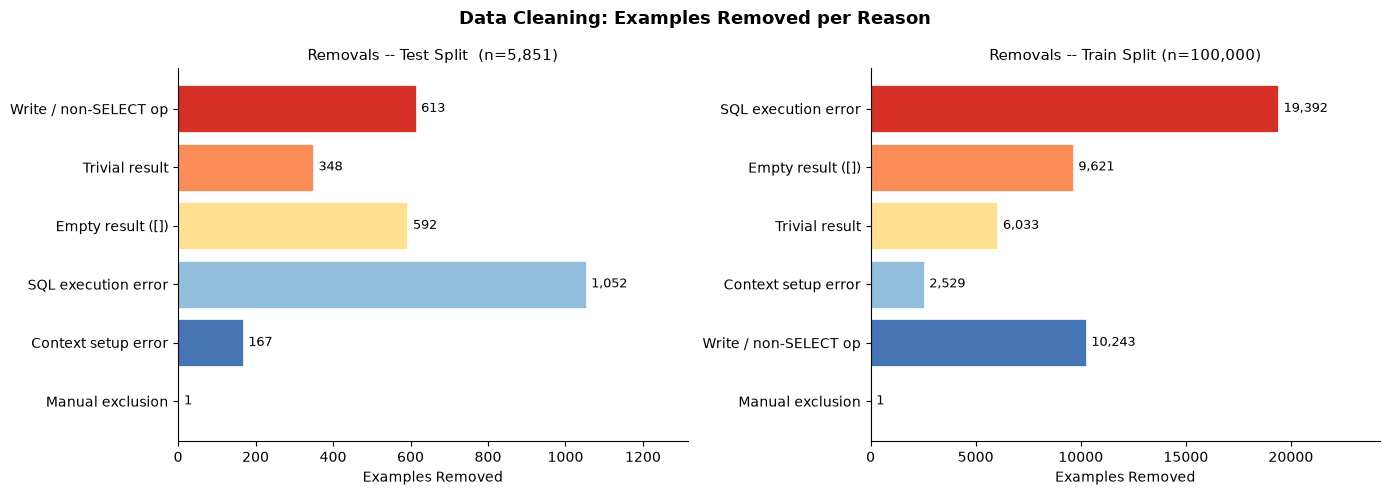

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = ["#d73027", "#fc8d59", "#fee090", "#91bfdb", "#4575b4", "#74add1", "#313695"]

for ax, (counts, split_name) in zip(axes, [
    (test_reason_counts,  f"Test Split  (n={len(raw_test):,})"),
    (train_reason_counts, f"Train Split (n={len(raw_train):,})"),
]):
    labels, values = list(counts.keys()), list(counts.values())
    bars = ax.barh(labels, values, color=palette[:len(labels)], edgecolor="white", linewidth=0.5)
    ax.set_xlabel("Examples Removed")
    ax.set_title(f"Removals -- {split_name}", fontsize=11)
    ax.bar_label(bars, labels=[f"{v:,}" for v in values], padding=4, fontsize=9)
    ax.set_xlim(0, max(values) * 1.25 if values else 1)
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Data Cleaning: Examples Removed per Reason", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 1.6 Generate the splits
1. 200 clean test examples from `clean_test`, stratified by `sql_complexity` (first 20 = QUICK_RUN subset).
2. 200 clean validation examples from the *remaining* clean test pool (disjoint from test).
3. Train = every clean train example (the RAG index and any fine-tuning use this only).

In [8]:
rng = random.Random(SEED)
test_rows, remainder = data.stratified_sample(clean_test, TEST_SIZE, rng)
val_rows, _ = data.stratified_sample(remainder, VAL_SIZE, rng)

test_ids = [r["id"] for r in test_rows]
val_ids = [r["id"] for r in val_rows]
train_ids = [r["id"] for r in clean_train]

data.save_json_list(test_ids_path, test_ids)
data.save_json_list(val_ids_path, val_ids)
data.save_json_list(train_ids_path, train_ids)

test_set, val_set = set(test_ids), set(val_ids)
assert not (test_set & val_set), "ERROR: test and val share IDs!"
print("Disjointness checks:")
print(f"  test & val ID overlap: {len(test_set & val_set)} [OK]")

print("\nFinal split sizes:")
print(f"  {test_ids_path.name:<15}: {len(test_ids):,} examples  (first {QUICK_TEST} = QUICK_RUN)")
print(f"  {val_ids_path.name:<15}: {len(val_ids):,} examples")
print(f"  {train_ids_path.name:<15}: {len(train_ids):,} examples")
print(f"\nQUICK_RUN subset (first {QUICK_TEST} test IDs):\n  {test_ids[:QUICK_TEST]}")

Disjointness checks:
  test & val ID overlap: 0 [OK]

Final split sizes:
  test_ids.json  : 200 examples  (first 20 = QUICK_RUN)
  val_ids.json   : 200 examples
  train_ids.json : 52,181 examples

QUICK_RUN subset (first 20 test IDs):
  [5610, 3193, 5576, 4929, 4484, 4644, 3510, 2691, 4728, 1684, 4542, 2914, 2740, 4669, 5278, 5323, 109, 1175, 1301, 5194]


In [9]:
test_comp = Counter(r["sql_complexity"] for r in test_rows)
val_comp = Counter(r["sql_complexity"] for r in val_rows)
train_comp = Counter(r["sql_complexity"] for r in clean_train)
all_comps = sorted(set(test_comp) | set(val_comp) | set(train_comp))

print("SQL Complexity Distribution:")
print(f"  {'Complexity':<25} {'Train':>9} {'Val':>6} {'Test':>6}")
print("  " + "-" * 52)
for comp in all_comps:
    print(f"  {comp:<25} {train_comp.get(comp, 0):>9,d} {val_comp.get(comp, 0):>6,d} {test_comp.get(comp, 0):>6,d}")

SQL Complexity Distribution:
  Complexity                    Train    Val   Test
  ----------------------------------------------------
  aggregation                  12,737     49     49
  basic SQL                    26,571    104    102
  multiple_joins                  903      3      4
  set operations                  536      2      2
  single join                   6,873     26     27
  subqueries                    2,606      8      9
  window functions              1,955      8      7


### 1.7 EDA: SQL complexity distribution

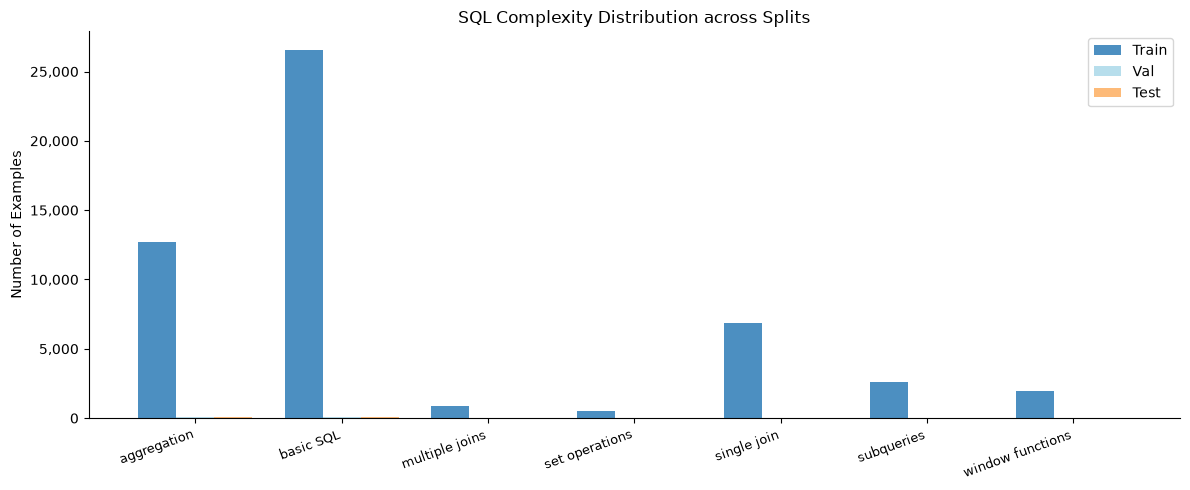

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(all_comps)); width = 0.26
colors = ["#2c7bb6", "#abd9e9", "#fdae61"]
ax.bar([i - width for i in x], [train_comp.get(c, 0) for c in all_comps], width, label="Train", color=colors[0], alpha=0.85)
ax.bar([i for i in x],         [val_comp.get(c, 0) for c in all_comps],   width, label="Val",   color=colors[1], alpha=0.85)
ax.bar([i + width for i in x], [test_comp.get(c, 0) for c in all_comps],  width, label="Test",  color=colors[2], alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels([c.replace("_", " ") for c in all_comps], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("Number of Examples")
ax.set_title("SQL Complexity Distribution across Splits", fontsize=12)
ax.legend()
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 1.8 EDA: top 20 domains (clean train)

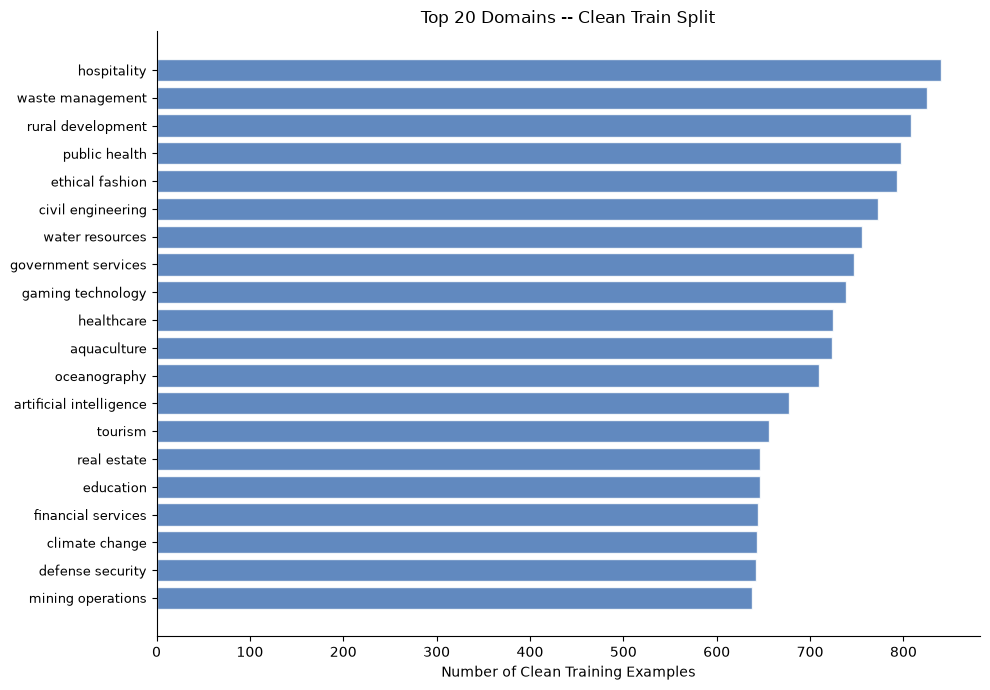

Total unique domains in clean train: 100


In [11]:
domain_counts = Counter(r["domain"] for r in clean_train)
labels, values = zip(*domain_counts.most_common(20))

fig, ax = plt.subplots(figsize=(10, 7))
y = range(len(labels))
ax.barh(list(y), list(values), color="#4575b4", alpha=0.85, edgecolor="white")
ax.set_yticks(list(y)); ax.set_yticklabels(list(labels), fontsize=9)
ax.set_xlabel("Number of Clean Training Examples")
ax.set_title("Top 20 Domains -- Clean Train Split", fontsize=12)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Total unique domains in clean train: {len(domain_counts)}")

### 1.9 EDA: prompt and SQL length distributions

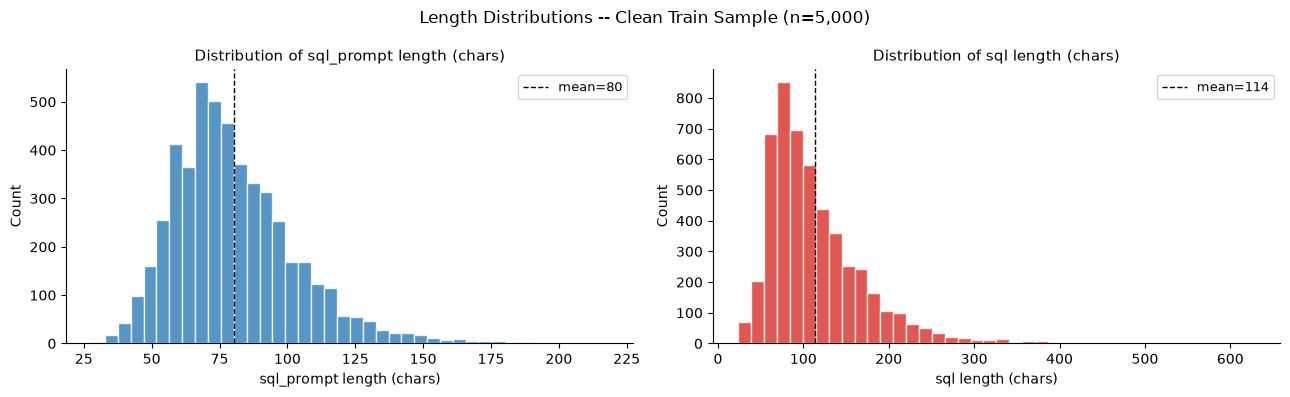

In [12]:
sample = random.Random(SEED).sample(clean_train, min(5000, len(clean_train)))
prompt_lens = [len(r["sql_prompt"]) for r in sample]
sql_lens = [len(r["sql"]) for r in sample]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, vals, label, color in zip(axes, [prompt_lens, sql_lens],
                                  ["sql_prompt length (chars)", "sql length (chars)"], ["#2c7bb6", "#d73027"]):
    mean = sum(vals) / len(vals)
    ax.hist(vals, bins=40, color=color, alpha=0.8, edgecolor="white")
    ax.axvline(mean, color="black", linestyle="--", linewidth=1, label=f"mean={mean:.0f}")
    ax.set_xlabel(label); ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {label}", fontsize=11)
    ax.legend(fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Length Distributions -- Clean Train Sample (n=5,000)", fontsize=12)
plt.tight_layout()
plt.show()

### 1.10 Overlap and leakage report

In [13]:
test_prompts = {r["sql_prompt"] for r in test_rows}
val_prompts = {r["sql_prompt"] for r in val_rows}
train_prompts = {r["sql_prompt"] for r in clean_train}

print("Prompt overlap (must be 0):")
print(f"  test  & train prompt overlap: {len(test_prompts & train_prompts):,}")
print(f"  val   & train prompt overlap: {len(val_prompts & train_prompts):,}")
print(f"  test  & val   prompt overlap: {len(test_prompts & val_prompts):,}")

test_contexts = {r["sql_context"] for r in test_rows}
val_contexts = {r["sql_context"] for r in val_rows}
train_contexts = {r["sql_context"] for r in clean_train}
print("\nsql_context (table schema) overlap:")
print(f"  test  & train context overlap: {len(test_contexts & train_contexts):,}  (shared table schemas)")
print(f"  val   & train context overlap: {len(val_contexts & train_contexts):,}  (shared table schemas)")
print("  Note: shared schemas are expected in a synthetic dataset;")
print("  what matters is that prompts and IDs do not overlap (all 0 above).")

print("\nLeakage safeguard:")
print("  * test_ids.json and val_ids.json are disjoint from train_ids.json")
print("  * The RAG index (Part 2) is built from train_ids.json only")
print("  * Do not index or train on any ID from test_ids.json or val_ids.json")

Prompt overlap (must be 0):
  test  & train prompt overlap: 0
  val   & train prompt overlap: 0
  test  & val   prompt overlap: 0

sql_context (table schema) overlap:
  test  & train context overlap: 16  (shared table schemas)
  val   & train context overlap: 21  (shared table schemas)
  Note: shared schemas are expected in a synthetic dataset;
  what matters is that prompts and IDs do not overlap (all 0 above).

Leakage safeguard:
  * test_ids.json and val_ids.json are disjoint from train_ids.json
  * The RAG index (Part 2) is built from train_ids.json only
  * Do not index or train on any ID from test_ids.json or val_ids.json


### 1.11 SQL harness self-tests

In [14]:
data.self_test_harness()
print("\nHarness self-tests complete.")

All 4 self-tests passed [OK]

Harness self-tests complete.


### 1.12 Filter report
`MANUAL_AUDIT` holds the summary of the manual review that is written to `filter_report.json`. When it is `None`, the default entry defined in `data.py` is used.

In [15]:
MANUAL_AUDIT = None

report = data.generate_filter_report(
    test_log=test_log, train_log=train_log,
    test_ids=test_ids, val_ids=val_ids, train_ids=train_ids,
    test_raw=len(raw_test), train_raw=len(raw_train),
    manual_audit=MANUAL_AUDIT,
)

print("\n=== Filter Report Summary ===")
print(f"\nTest split ({report['test_split']['raw_total']:,} raw):")
for reason, count in report["test_split"]["removed_by_reason"].items():
    print(f"  {reason:<28}: {count:,}")
print(f"  Clean pool                  : {report['test_split']['clean_pool_size']:,}")

print(f"\nTrain split ({report['train_split']['raw_total']:,} raw):")
for reason, count in report["train_split"]["removed_by_reason"].items():
    print(f"  {reason:<28}: {count:,}")
print(f"  Clean total                 : {report['train_split']['clean_total']:,}")

print("\nFinal splits:")
for k, v in report["final_splits"].items():
    print(f"  {k:<25}: {v:,}")
print(f"\nManual audit status: {report['manual_audit']['status']}")

Filter report saved -> filter_report.json

=== Filter Report Summary ===

Test split (5,851 raw):
  write_or_non_select         : 613
  trivial_result              : 348
  empty_result                : 592
  sql_execution_error         : 1,052
  context_setup_error         : 167
  manual_exclusion            : 1
  Clean pool                  : 3,078

Train split (100,000 raw):
  sql_execution_error         : 19,392
  empty_result                : 9,621
  trivial_result              : 6,033
  context_setup_error         : 2,529
  write_or_non_select         : 10,243
  manual_exclusion            : 1
  Clean total                 : 52,181

Final splits:
  test                     : 200
  val                      : 200
  train_clean_total        : 52,181
  quick_run_subset         : 20

Manual audit status: pending manual review (1 example pre-flagged as reference)


### 1.13 Consistency check against the reference figures

In [16]:
REFERENCE = {"clean test pool": (len(clean_test), 3078), "clean train": (len(clean_train), 52181),
             "test": (len(test_ids), 200), "val": (len(val_ids), 200)}
for name, (got, ref) in REFERENCE.items():
    print(f"  {name:<16}: {got:>7,d}  (reference: {ref:,})  {'[OK]' if got == ref else '[differs]'}")
print("\nDifferences arise only when additional manual exclusions are recorded in excluded_ids.json.")

  clean test pool :   3,078  (reference: 3,078)  [OK]
  clean train     :  52,181  (reference: 52,181)  [OK]
  test            :     200  (reference: 200)  [OK]
  val             :     200  (reference: 200)  [OK]

Differences arise only when additional manual exclusions are recorded in excluded_ids.json.


### 1.14 Manual audit
Examples that pass every filter can still be unsuitable: the gold SQL may not answer the question, the question may be ambiguous, or the result may be trivial. `AUDIT_N` test examples are displayed in blocks of ten (`AUDIT_START` = 0, 10, 20, ...). Examples judged unsuitable are added to `test_exclusions` in `excluded_ids.json`, after which Part 1 is re-run.

In [17]:
AUDIT_N, AUDIT_START = 60, 0
test_idx = {i: k for k, i in enumerate(raw_test["id"])}

def show_audit(split, index, ids, start=0, n=10):
    for i in ids[start:start + n]:
        ex = split[index[i]]
        rows, err = run_sql(ex["sql_context"], ex["sql"])
        print("=" * 70)
        print(f"id {i} | {ex['sql_complexity']} | {ex['domain']}")
        print("Q:     ", ex["sql_prompt"])
        print("SCHEMA:", ex["sql_context"][:350].replace("\n", " "))
        print("GOLD:  ", ex["sql"])
        print("RESULT:", (rows or [])[:5], f"({len(rows or [])} rows)")

show_audit(raw_test, test_idx, test_ids[:AUDIT_N], start=AUDIT_START, n=10)

id 5610 | basic SQL | space
Q:      Find the total mass of all space debris in Geostationary Orbit (GSO) that originate from defunct satellites.
SCHEMA: CREATE TABLE gso_debris (id INT, name VARCHAR(50), type VARCHAR(50), orbit VARCHAR(50), mass FLOAT, source VARCHAR(50)); INSERT INTO gso_debris (id, name, type, orbit, mass, source) VALUES (1, 'Debris1', 'Panel', 'GSO', 50.3, 'Defunct Satellite'), (2, 'Debris2', 'Bolt', 'GSO', 0.05, 'Rocket Body'), (3, 'Debris3', 'Rod', 'GSO', 2.8, 'Defunct Satelli
GOLD:   SELECT SUM(mass) FROM gso_debris WHERE orbit = 'GSO' AND source = 'Defunct Satellite';
RESULT: [(53.099999999999994,)] (1 rows)
id 3193 | aggregation | automotive
Q:      What is the adoption rate of electric vehicles in major cities?
SCHEMA: CREATE TABLE ElectricVehicleAdoption (City VARCHAR(50), Make VARCHAR(50), Model VARCHAR(50), Year INT, Adoption DECIMAL(5,2)); INSERT INTO ElectricVehicleAdoption (City, Make, Model, Year, Adoption) VALUES ('Los Angeles', 'Tesla', 'Model 3', 202

### 1.15 Runtime summary

In [18]:
elapsed = time.time() - _notebook_start
print(f"Part 1 completed in {elapsed:.1f} seconds ({elapsed / 60:.1f} minutes)")
print("Files saved:")
for fname in [test_ids_path.name, val_ids_path.name, train_ids_path.name, excluded_path.name, Path(CONFIG.get("filter_report_path", "filter_report.json")).name,
              "cleaning_removal_reasons.png", "eda_complexity_distribution.png",
              "eda_domain_distribution.png", "eda_length_distributions.png"]:
    p = Path(fname)
    print(f"  {fname:<40} {f'{p.stat().st_size:,} bytes' if p.exists() else 'NOT FOUND'}")

Part 1 completed in 15.9 seconds (0.3 minutes)
Files saved:
  test_ids.json                            1,560 bytes
  val_ids.json                             1,559 bytes
  train_ids.json                           463,819 bytes
  excluded_ids.json                        297 bytes
  filter_report.json                       1,157 bytes
  cleaning_removal_reasons.png             NOT FOUND
  eda_complexity_distribution.png          NOT FOUND
  eda_domain_distribution.png              NOT FOUND
  eda_length_distributions.png             NOT FOUND


# Part 2: Retrieval-augmented generation

Few-shot examples are retrieved from the clean training split and inserted into the prompt of a SQLite text-to-SQL model. Generated queries are executed against the example's database and counted as correct when the result matches the gold query's result (execution accuracy).

**Design decisions**
- *Splits.* The validation set (`val_ids.json`) and the test set (`test_ids.json`) are drawn from the official test split in proportion to SQL complexity, so both measure the same distribution. The retrieval index is built from `train_ids.json` only, after removing any question that also occurs in validation or test.
- *Model selection.* All retrieval settings and the prompt style are selected on the validation set. The test set is evaluated once.
- *Prompt styles.* Two prompt styles are compared on validation. **original**: example schemas are shown as `CREATE TABLE` statements, the target schema in full, and `SELECT *` is forbidden. **strict**: example schemas are shown in full, examples are numbered, and the model is instructed to use only the tables and columns of the final schema.

### 2.1 Settings

In [19]:
K_GRID = [3, 5]               # number of retrieved examples to compare
RUN_SKELETON = True           # skeleton retrieval is slower (needs a zero-shot draft); set False to skip
BATCH_SIZE = 4
PROMPT_STYLE = "auto"         # "original" | "strict" | "auto" (selected on validation in 2.7)
INDEX_N = None                # optional cap on the index size

QUICK_VAL = 40
print(f"Quick Run: {QUICK_RUN} | INDEX_N: {INDEX_N} | K_GRID: {K_GRID} | skeleton: {RUN_SKELETON}")

Quick Run: False | INDEX_N: None | K_GRID: [3, 5] | skeleton: True


### 2.2 Splits from the saved ID files
Validation and test examples come from the official test split and training examples from the official train split. Part 2 uses the ID files written in Part 1; no further splitting takes place.

In [20]:
def pick(split, ids):
    idx = {i: k for k, i in enumerate(split["id"])}
    return split.select([idx[i] for i in ids if i in idx])

train_all = pick(raw_train, train_ids)
val_ds = pick(raw_test, val_ids)
test_ds = pick(raw_test, test_ids)
print("train:", len(train_all), "| val:", len(val_ds), "| test:", len(test_ds))

val_eval = val_ds.select(range(min(QUICK_VAL, len(val_ds)))) if QUICK_RUN else val_ds
test_eval = test_ds.select(range(min(QUICK_TEST, len(test_ds)))) if QUICK_RUN else test_ds

train: 52181 | val: 200 | test: 200


### 2.3 Schema helpers and question masking
Masking replaces table names, column names, quoted values and numbers in the question with placeholders, so retrieval matches the *shape* of the question rather than its topic words.

In [21]:
SCHEMA_MODE = "full"          # "full" = whole sql_context, "create" = CREATE statements only

def schema_text(ctx, mode=None):
    mode = mode or SCHEMA_MODE
    if mode == "create":
        stmts = re.findall(r"CREATE\s+TABLE[^;]*;", ctx, flags=re.I | re.S)
        return "\n".join(stmts) if stmts else ctx
    return ctx

def schema_names(ctx):
    """Table and column names from the CREATE TABLE statements."""
    tables, cols = set(), set()
    pat = r"CREATE\s+TABLE\s+(?:IF NOT EXISTS\s+)?[`\"\[]?(\w+)[`\"\]]?\s*\((.*?)\)\s*;"
    for m in re.finditer(pat, ctx, flags=re.I | re.S):
        tables.add(m.group(1))
        depth, cur, parts = 0, "", []
        for ch in m.group(2):
            if ch == "(":
                depth += 1
            if ch == ")":
                depth -= 1
            if ch == "," and depth == 0:
                parts.append(cur); cur = ""
            else:
                cur += ch
        parts.append(cur)
        for p in parts:
            tok = p.strip().split()
            if tok and tok[0].upper() not in ("PRIMARY", "FOREIGN", "UNIQUE", "CONSTRAINT", "CHECK"):
                cols.add(tok[0].strip('`"[]'))
    return tables, cols

def mask_question(q, ctx):
    tables, cols = schema_names(ctx)
    out = q
    names = [(n, "<T>") for n in sorted(tables, key=len, reverse=True)] + \
            [(n, "<C>") for n in sorted(cols, key=len, reverse=True)]
    for name, tag in names:
        for v in sorted({name, name.replace("_", " ")}, key=len, reverse=True):
            out = re.sub(rf"\b{re.escape(v)}s?\b", tag, out, flags=re.I)
    out = re.sub(r"'[^']*'|\"[^\"]*\"", "<V>", out)
    out = re.sub(r"\b\d[\d,\.]*\b", "<N>", out)
    return out

for ex in test_ds.select(range(3)):
    print(ex["sql_prompt"], "\n  ->", mask_question(ex["sql_prompt"], ex["sql_context"]))

Find the total mass of all space debris in Geostationary Orbit (GSO) that originate from defunct satellites. 
  -> Find the total <C> of all space debris in Geostationary <C> (GSO) that originate from defunct satellites.
What is the adoption rate of electric vehicles in major cities? 
  -> What is the <C> rate of electric vehicles in major cities?
Who are the top 5 users with the most followers, and what is their location? 
  -> Who are the top <N> users with the most <C>, and what is their <C>?


### 2.4 Build the indexes (from the clean train split only)
The retrieval pool is `train_ids.json` minus (a) any question that also appears in validation or test, and (b) repeated questions. The shared ID files are not touched.

In [22]:
import torch, faiss, hashlib
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi

norm = lambda s: re.sub(r"\s+", " ", s.lower().strip())
blocked = {norm(q) for q in val_ds["sql_prompt"]} | {norm(q) for q in test_ds["sql_prompt"]}

seen, keep, n_leak, n_dup = set(), [], 0, 0
for k, q in enumerate(train_all["sql_prompt"]):
    nq = norm(q)
    if nq in blocked: n_leak += 1; continue
    if nq in seen: n_dup += 1; continue
    seen.add(nq); keep.append(k)

pool = train_all.select(keep)
if INDEX_N is not None:
    pool = pool.shuffle(seed=SEED).select(range(min(INDEX_N, len(pool))))
pool_q, pool_ctx, pool_sql = pool["sql_prompt"], pool["sql_context"], pool["sql"]
print(f"train {len(train_all):,} -> index {len(pool_q):,} (dropped {n_leak} val/test questions, {n_dup} repeated questions)")

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(CONFIG["embedder"], device=device)

def embed(texts, bar=False):
    return embedder.encode(texts, batch_size=128, normalize_embeddings=True, show_progress_bar=bar).astype("float32")

def cached_embed(tag, texts):
    """Embeddings are cached on disk, keyed by model name and text, so re-runs are instant."""
    key = hashlib.md5((CONFIG["embedder"] + "\n".join(texts)).encode()).hexdigest()[:10]
    f = CACHE / f"emb_{tag}_{key}.npy"
    if f.exists():
        return np.load(f)
    v = embed(texts, bar=True); np.save(f, v)
    return v

def build_faiss(vecs):
    index = faiss.IndexFlatIP(vecs.shape[1]); index.add(vecs)
    return index

pool_masked = [mask_question(q, c) for q, c in zip(pool_q, pool_ctx)]
index_dense = build_faiss(cached_embed("dense", pool_q))
index_masked = build_faiss(cached_embed("masked", pool_masked))
tokenize = lambda s: re.findall(r"\w+", s.lower())
bm25 = BM25Okapi([tokenize(q) for q in pool_q])

# leakage check: no validation or test question may be inside the index
leak = {norm(q) for q in pool_q} & blocked
print("val/test questions found in the index:", len(leak))
assert not leak

train 52,181 -> index 52,160 (dropped 0 val/test questions, 21 repeated questions)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/408 [00:00<?, ?it/s]

Batches:   0%|          | 0/408 [00:00<?, ?it/s]

val/test questions found in the index: 0


### 2.5 `retrieve` (dense, bm25, hybrid RRF, masked) and skeleton retrieval

In [23]:
def _dense(index, text, n):
    _, I = index.search(embed([text]), n)
    return [int(i) for i in I[0] if i >= 0]

def _bm25(text, n):
    return [int(i) for i in np.argsort(-bm25.get_scores(tokenize(text)))[:n]]

def _rrf(*rankings):
    score = {}
    for ranking in rankings:
        for rank, i in enumerate(ranking):
            score[i] = score.get(i, 0) + 1 / (60 + rank + 1)
    return sorted(score, key=score.get, reverse=True)

def _as_examples(ids):
    return [{"sql_prompt": pool_q[i], "sql_context": pool_ctx[i], "sql": pool_sql[i]} for i in ids]

def retrieve(question, k=3, mode="dense", schema=None):
    """Return k similar solved examples. mode: dense | bm25 | hybrid (RRF) | masked."""
    if k == 0:
        return []
    if mode == "dense":
        ids = _dense(index_dense, question, k)
    elif mode == "bm25":
        ids = _bm25(question, k)
    elif mode == "hybrid":
        ids = _rrf(_dense(index_dense, question, 50), _bm25(question, 50))[:k]
    elif mode == "masked":
        ids = _dense(index_masked, mask_question(question, schema or ""), k)
    else:
        raise ValueError(mode)
    return _as_examples(ids)

def random_examples(q, k=3):
    return _as_examples(random.Random(f"{SEED}-{q}").sample(range(len(pool_q)), k))

# ---- skeleton retrieval: match the *SQL shape* of a zero-shot draft ----
KW = set("""SELECT FROM WHERE GROUP BY ORDER HAVING JOIN INNER LEFT RIGHT OUTER FULL CROSS ON AS AND OR NOT IN EXISTS UNION ALL INTERSECT EXCEPT LIMIT OFFSET DISTINCT COUNT SUM AVG MIN MAX OVER PARTITION CASE WHEN THEN ELSE END LIKE BETWEEN IS NULL DESC ASC WITH ROW_NUMBER RANK DENSE_RANK LAG LEAD""".split())

def skeleton(sql):
    s = re.sub(r"'[^']*'", " <V> ", sql)
    s = re.sub(r"\b\d+(?:\.\d+)?\b", " <N> ", s)
    out = []
    for t in re.findall(r"<V>|<N>|\w+|[^\s\w]", s):
        if t in ("<V>", "<N>") or not re.match(r"\w", t): out.append(t)
        elif t.upper() in KW: out.append(t.upper())
        else: out.append("<I>")
    return " ".join(out)

if RUN_SKELETON:
    bm25_skel = BM25Okapi([skeleton(s).split() for s in pool_sql])

def retrieve_skeleton(question, ctx, k, draft):
    r1 = _dense(index_masked, mask_question(question, ctx), 50)
    r2 = [int(i) for i in np.argsort(-bm25_skel.get_scores(skeleton(draft).split()))[:50]]
    return _as_examples(_rrf(r1, r2)[:k])

ex = val_ds[0]
for r in retrieve(ex["sql_prompt"], 3, "masked", ex["sql_context"]):
    print(r["sql_prompt"], "->", r["sql"])

What is the average account balance for clients in Oceania in Q2 2022? -> SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('Australia', 'New Zealand', 'Papua New Guinea') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';
What is the average account balance for clients in the Southeast region? -> SELECT AVG(balance) FROM accounts WHERE region = 'Southeast';
What is the average financial wellbeing score for customers in Asia in 2021? -> SELECT AVG(score) FROM financial_wellbeing WHERE region = 'Asia' AND year = 2021;


### 2.6 `generate` (zero-shot, few-shot, batched) and `evaluate`
Two prompt styles are compared in 2.7:
- **original**: example schemas are shown as `CREATE TABLE` statements only, the target schema in full, and `SELECT *` is forbidden.
- **strict**: the later prompt. Examples show the full schema (with `INSERT` rows), numbered headers, and an instruction to use only the last schema.

In [24]:
from transformers import AutoTokenizer, AutoModelForCausalLM

llm_tok = AutoTokenizer.from_pretrained(CONFIG["llm"])
if llm_tok.pad_token is None:
    llm_tok.pad_token = llm_tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(
    CONFIG["llm"], dtype=torch.float16 if device == "cuda" else torch.float32
).to(device).eval()

SYSTEM_ORIGINAL = (
    "You are a SQLite expert. Write exactly one SQLite SELECT query that answers the question. Return only the SQL. "
    "Use ONLY SQLite-compatible syntax - do NOT use YEAR(), MONTH(), DATE_FORMAT(), or any MySQL function. "
    "For dates use strftime() or string comparison. "
    "Never use SELECT * - always select only the columns the question asks for. "
    "Return only the SQL query, do not include any explanation or additional text, no markdown."
)
SYSTEM_STRICT = (
    "You are a SQLite expert. Write exactly one SQLite SELECT query that answers the question. "
    "Use ONLY SQLite-compatible syntax: no YEAR(), MONTH(), DATE_FORMAT() or other MySQL functions. "
    "For dates use strftime() or string comparison. "
    "Use ONLY the table and column names from the LAST schema given. "
    "Return only the SQL, with no explanation and no markdown."
)
PROMPTS = {"original": dict(system=SYSTEM_ORIGINAL, ex_schema="create", numbered=False),
           "strict":   dict(system=SYSTEM_STRICT,   ex_schema="full",   numbered=True)}

def build_messages(question, schema, examples=None, style="original"):
    p = PROMPTS[style]
    parts = []
    for n, e in enumerate(examples or [], 1):
        head = f"### Example {n}\n" if p["numbered"] else ""
        parts.append(f"{head}Schema:\n{schema_text(e['sql_context'], mode=p['ex_schema'])}\n"
                     f"Question: {e['sql_prompt']}\nSQL: {e['sql']}")
    head = "### Now solve this one. Use ONLY the tables and columns in this schema.\n" if p["numbered"] else ""
    parts.append(f"{head}Schema:\n{schema_text(schema, mode='full')}\nQuestion: {question}\nSQL:")
    return [{"role": "system", "content": p["system"]}, {"role": "user", "content": "\n\n".join(parts)}]

def clean_sql(text):
    text = re.sub(r"```(?:sql)?", "", text, flags=re.I).strip()
    text = re.sub(r"^\s*SQL:\s*", "", text, flags=re.I)
    stmt = text.split(";")[0].strip()
    return stmt + ";" if stmt else ""

def generate_batch(items, style="original", batch_size=BATCH_SIZE):
    """items: list of (question, schema, examples or None). Returns SQL strings in the same order."""
    texts = [llm_tok.apply_chat_template(build_messages(q, s, e, style), tokenize=False, add_generation_prompt=True)
             for q, s, e in items]
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))    # similar lengths together = less padding
    outs = [None] * len(texts)
    llm_tok.padding_side = "left"
    for b in range(0, len(order), batch_size):
        idx = order[b:b + batch_size]
        inputs = llm_tok([texts[i] for i in idx], return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            out = llm.generate(**inputs, max_new_tokens=256, do_sample=False,
                               pad_token_id=llm_tok.pad_token_id or llm_tok.eos_token_id)
        for j, i in enumerate(idx):
            outs[i] = clean_sql(llm_tok.decode(out[j][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
    return outs

def generate(question, schema, examples=None, style="original"):
    """examples=None -> zero-shot, otherwise few-shot. Returns one SQL string."""
    return generate_batch([(question, schema, examples)], style, 1)[0]

ex = val_ds[0]
print("gold:", ex["sql"])
print("zero:", generate(ex["sql_prompt"], ex["sql_context"]))
print("few: ", generate(ex["sql_prompt"], ex["sql_context"], retrieve(ex["sql_prompt"], 3, "masked", ex["sql_context"])))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

gold: SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('India', 'China', 'Japan') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';
zero: SELECT AVG(balance) FROM accounts WHERE strftime('%Y-%m', account_date) BETWEEN '2022-04' AND '2022-06' AND country IN ('India', 'China');
few:  SELECT AVG(balance) as avg_balance FROM accounts WHERE country IN ('China', 'Japan') AND account_date BETWEEN '2022-04-01' AND '2022-06-30';


In [25]:
def evaluate_batched(name, subset, examples_list, style, t0=None):
    """Runs generation for every example, executes pred and gold, saves per-example results to results/<name>.json."""
    t0 = t0 or time.time()
    subset = list(subset)
    preds = generate_batch([(e["sql_prompt"], e["sql_context"], x) for e, x in zip(subset, examples_list)], style)
    per_ex = round((time.time() - t0) / max(len(subset), 1), 3)
    rows = []
    for e, pred in zip(subset, preds):
        p_rows, err = run_sql(e["sql_context"], pred)
        g_rows, _ = run_sql(e["sql_context"], e["sql"])
        rows.append({"id": e["id"], "complexity": e["sql_complexity"], "question": e["sql_prompt"],
                     "pred": pred, "gold": e["sql"], "error": err,
                     "correct": bool(err is None and same_result(p_rows, g_rows)), "sec": per_ex})
    df = pd.DataFrame(rows)
    Path("results").mkdir(exist_ok=True)
    df.to_json(f"results/{name}.json", orient="records", indent=1)
    return df

def run_system(name, mode, k, subset, style, tag=None):
    """mode: zero | random | dense | bm25 | hybrid | masked | skeleton. Includes retrieval time in `sec`."""
    t0 = time.time()
    subset = list(subset)
    if mode == "zero":
        exs = [None] * len(subset)
    elif mode == "random":
        exs = [random_examples(e["sql_prompt"], k) for e in subset]
    elif mode == "skeleton":
        drafts = generate_batch([(e["sql_prompt"], e["sql_context"], None) for e in subset], style)
        exs = [retrieve_skeleton(e["sql_prompt"], e["sql_context"], k, d) for e, d in zip(subset, drafts)]
    else:
        exs = [retrieve(e["sql_prompt"], k, mode, schema=e["sql_context"]) for e in subset]
    return evaluate_batched(tag or name, subset, exs, style, t0)

def paired_gain(name, base="zero_shot", n=2000, seed=0):
    """Mean accuracy gain over `base` on the same questions, with a paired-bootstrap 95% CI."""
    a = pd.read_json(f"results/{base}.json").set_index("id").correct.astype(float)
    b = pd.read_json(f"results/{name}.json").set_index("id").correct.astype(float)
    d = (b - a.loc[b.index]).values
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d)).mean() for _ in range(n)]
    return round(d.mean(), 3), tuple(np.percentile(m, [2.5, 97.5]).round(3))

SYSTEMS = {"zero_shot": ("zero", 0), "random_k3": ("random", 3)}
for mode in ["dense", "bm25", "hybrid", "masked"]:
    for k in K_GRID:
        SYSTEMS[f"{mode}_k{k}"] = (mode, k)
if RUN_SKELETON:
    SYSTEMS["skeleton_k3"] = ("skeleton", 3)
print(list(SYSTEMS))

['zero_shot', 'random_k3', 'dense_k3', 'dense_k5', 'bm25_k3', 'bm25_k5', 'hybrid_k3', 'hybrid_k5', 'masked_k3', 'masked_k5', 'skeleton_k3']


### 2.7 Compare settings on the validation set
All settings are selected on the validation set; the test set is not used for tuning.

**Step 1: prompt ablation.** Three representative systems are evaluated under both prompt styles. The style with the higher mean validation accuracy is used in all subsequent runs, unless `PROMPT_STYLE` is set explicitly.

In [26]:
import shutil; shutil.rmtree("results", ignore_errors=True)     # clear results of previous runs

ABLATE = ["zero_shot", "bm25_k3", "masked_k3"]
abl = []
for style in PROMPTS:
    for name in ABLATE:
        mode, k = SYSTEMS[name]
        d = run_system(name, mode, k, val_eval, style, tag=f"abl_{style}_{name}")
        abl.append({"style": style, "system": name, "exec_acc": round(d.correct.mean(), 3)})
abl = pd.DataFrame(abl).pivot(index="style", columns="system", values="exec_acc")[ABLATE]
abl["mean"] = abl.mean(axis=1).round(3)
display(abl)

if PROMPT_STYLE == "auto":
    PROMPT_STYLE = abl["mean"].idxmax()
print("Prompt style used from here on:", PROMPT_STYLE)

system,zero_shot,bm25_k3,masked_k3,mean
style,,,,
original,0.58,0.615,0.625,0.607
strict,0.58,0.665,0.655,0.633


Prompt style used from here on: strict


**Step 2: retrieval settings.** Zero-shot, random examples, dense, BM25, hybrid, masked and skeleton retrieval, with k in `K_GRID`.

In [27]:
table = []
for name, (mode, k) in SYSTEMS.items():
    df = run_system(name, mode, k, val_eval, PROMPT_STYLE)
    row = {"system": name, "exec_acc": round(df.correct.mean(), 3), "avg_sec": round(df.sec.mean(), 2)}
    if name != "zero_shot":
        g, ci = paired_gain(name)
        row["gain_vs_zero"], row["95% CI"] = g, ci
    table.append(row)
val_table = pd.DataFrame(table)
display(val_table)
val_table.to_csv("results/val_table.csv", index=False)

accs = {n: pd.read_json(f"results/{n}.json").groupby("complexity").correct.mean().round(2) for n in SYSTEMS}
print("\nAccuracy by SQL complexity (validation):")
display(pd.DataFrame(accs))

,system,exec_acc,avg_sec,gain_vs_zero,95% CI
0,zero_shot,0.580,0.20,NaN,NaN
1,random_k3,0.595,0.27,0.015,"(-0.025, 0.055)"
2,dense_k3,0.665,0.25,0.085,"(0.02, 0.15)"
3,dense_k5,0.680,0.30,0.100,"(0.035, 0.165)"
4,bm25_k3,0.665,0.31,0.085,"(0.02, 0.15)"
5,bm25_k5,0.645,0.36,0.065,"(0.0, 0.13)"
6,hybrid_k3,0.660,0.33,0.080,"(0.015, 0.145)"
7,hybrid_k5,0.675,0.38,0.095,"(0.035, 0.155)"
8,masked_k3,0.655,0.26,0.075,"(0.015, 0.135)"
9,masked_k5,0.660,0.30,0.080,"(0.025, 0.135)"



Accuracy by SQL complexity (validation):


,zero_shot,random_k3,dense_k3,dense_k5,bm25_k3,bm25_k5,hybrid_k3,hybrid_k5,masked_k3,masked_k5,skeleton_k3
complexity,,,,,,,,,,,
aggregation,0.39,0.47,0.57,0.61,0.59,0.53,0.55,0.57,0.57,0.59,0.55
basic SQL,0.74,0.76,0.81,0.80,0.78,0.79,0.79,0.81,0.78,0.77,0.79
multiple_joins,0.67,0.67,0.33,0.33,0.67,0.67,0.33,0.33,0.33,0.67,0.33
set operations,0.50,0.50,1.00,1.00,0.50,0.50,0.50,0.50,0.50,0.50,0.50
single join,0.58,0.50,0.50,0.54,0.50,0.50,0.58,0.58,0.54,0.54,0.46
subqueries,0.12,0.00,0.25,0.38,0.50,0.25,0.38,0.38,0.38,0.38,0.38
window functions,0.12,0.12,0.38,0.38,0.38,0.38,0.38,0.38,0.38,0.38,0.38


### 2.8 Error analysis: cases where retrieval hurt
Examples answered correctly in the zero-shot setting and incorrectly with the best retrieval setting. Typical causes are a misleading retrieved example and copied table or column names.

In [28]:
cands = val_table[~val_table.system.isin(["zero_shot", "random_k3"])].sort_values(["exec_acc", "avg_sec"], ascending=[False, True])
BEST = cands.iloc[0].system
print("Best retrieval setting on validation:", BEST, "| exec_acc:", cands.iloc[0].exec_acc)

a = pd.read_json("results/zero_shot.json")
b = pd.read_json(f"results/{BEST}.json")
m = a.merge(b, on="id", suffixes=("_zero", "_rag"))
hurt = m[m.correct_zero & ~m.correct_rag]
print(len(hurt), "examples where retrieval hurt\n")
for _, r in hurt.head(5).iterrows():
    print("ID:", r.id, "| Q:", r.question_zero, "\n gold:", r.gold_zero, "\n zero:", r.pred_zero,
          "\n rag: ", r.pred_rag, "\n err: ", r.error_rag, "\n")

Best retrieval setting on validation: dense_k5 | exec_acc: 0.68
13 examples where retrieval hurt

ID: 1316 | Q: List the ports and their average cargo weight for company "HarborLink" in Q2 2017 and Q3 2017. 
 gold: SELECT port.name, AVG(cargo.weight) FROM port INNER JOIN cargo ON port.id = cargo.port_id AND cargo.quarter IN (2, 3) INNER JOIN company ON cargo.company_id = company.id WHERE company.name = 'HarborLink' GROUP BY port.name; 
 zero: SELECT T2.name, AVG(T1.weight) FROM cargo AS T1 INNER JOIN port AS T2 ON T1.port_id = T2.id WHERE T1.company_id = (SELECT id FROM company WHERE name = 'HarborLink') AND T1.quarter IN (2, 3) GROUP BY T2.name; 
 rag:  SELECT port.name, AVG(c.weight) as avg_weight FROM port INNER JOIN cargo ON port.id = cargo.port_id AND cargo.quarter IN (2, 3) AND cargo.year = 2017 INNER JOIN company ON cargo.company_id = company.id WHERE company.name = 'HarborLink' GROUP BY port.name; 
 err:  SQL operational error: no such column: c.weight 

ID: 4097 | Q: What is t

In [29]:
# Does retrieval make the model copy table/column names from the examples?
for n in ["zero_shot", "random_k3", "dense_k3", "bm25_k3", "masked_k3"] + (["skeleton_k3"] if RUN_SKELETON else []):
    e = pd.read_json(f"results/{n}.json").error.fillna("").str.lower()
    print(f"{n:<12} | no such table: {e.str.contains('no such table').mean():.3f}"
          f" | no such column: {e.str.contains('no such column').mean():.3f}"
          f" | any error: {(e != '').mean():.3f}")

zero_shot    | no such table: 0.020 | no such column: 0.020 | any error: 0.045
random_k3    | no such table: 0.005 | no such column: 0.050 | any error: 0.055
dense_k3     | no such table: 0.030 | no such column: 0.045 | any error: 0.080
bm25_k3      | no such table: 0.030 | no such column: 0.045 | any error: 0.085
masked_k3    | no such table: 0.005 | no such column: 0.035 | any error: 0.050
skeleton_k3  | no such table: 0.005 | no such column: 0.030 | any error: 0.040


### 2.9 Final test evaluation
Zero-shot generation, random examples and the best retrieval setting from the validation table are evaluated once on the test set.

In [30]:
RUN_TEST = True
mode_b, k_b = SYSTEMS[BEST]
FINAL = {"zero_shot": SYSTEMS["zero_shot"], "random_k3": SYSTEMS["random_k3"], BEST: (mode_b, k_b)}

if RUN_TEST:
    rows = []
    for name, (mode, k) in FINAL.items():
        d = run_system(name, mode, k, test_eval, PROMPT_STYLE, tag=f"test_{name}")
        row = {"system": name, "exec_acc": round(d.correct.mean(), 3), "avg_sec": round(d.sec.mean(), 2)}
        if name != "zero_shot":
            g, ci = paired_gain(f"test_{name}", base="test_zero_shot")
            row["gain_vs_zero"], row["95% CI"] = g, ci
        rows.append(row)
    print(f"Test set: {len(test_eval)} questions | prompt style: {PROMPT_STYLE}")
    display(pd.DataFrame(rows))
    print("\nTest accuracy by SQL complexity:")
    display(pd.DataFrame({n: pd.read_json(f"results/test_{n}.json").groupby("complexity").correct.mean().round(2)
                          for n in FINAL}))

Test set: 200 questions | prompt style: strict


,system,exec_acc,avg_sec,gain_vs_zero,95% CI
0,zero_shot,0.570,0.19,NaN,NaN
1,random_k3,0.630,0.25,0.060,"(0.005, 0.11)"
2,dense_k5,0.675,0.30,0.105,"(0.04, 0.175)"



Test accuracy by SQL complexity:


,zero_shot,random_k3,dense_k5
complexity,,,
aggregation,0.33,0.53,0.65
basic SQL,0.78,0.79,0.80
multiple_joins,0.75,0.75,0.75
set operations,0.00,0.50,0.00
single join,0.37,0.44,0.41
subqueries,0.33,0.22,0.44
window functions,0.29,0.14,0.43
